# Object detection — look at your data first

Most failed projects fail here, not in the model. Before training anything, answer:
1. **How many objects per image, and of which classes?** (empty images and crowded images need different care)
2. **How big are the objects?** (tiny objects need a larger `image_size`)
3. **Do the boxes actually sit on the objects?** (wrong box format is the #1 detection bug — draw them and look)

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/detection/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("detection", cfg)
print("task:", "detection", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: detection | data: data/demo/detection | outputs: outputs/detection_quick


## How the data is organised
COCO format: an `images/` folder and one `annotations.json` listing every image, class and box (`bbox = [x, y, width, height]` in pixels). See [docs/data-formats.md](../../../docs/data-formats.md) for a worked example and YOLO / Pascal VOC conversion.

## Objects per image and per class

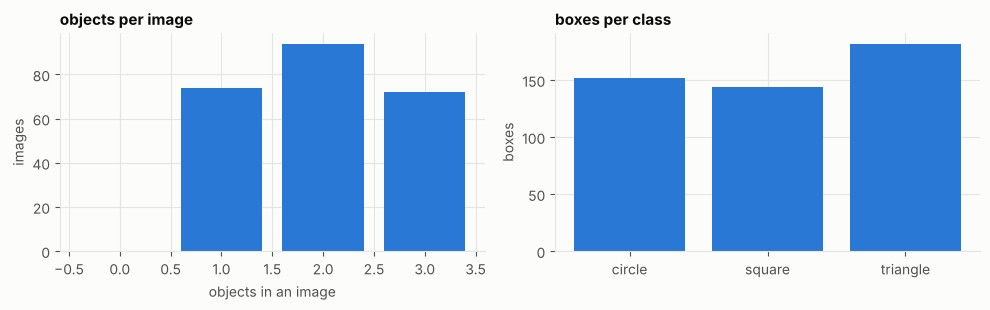

240 images, 478 boxes, 0 images with no objects


In [3]:
from PIL import Image
from cvkit.coco import load_coco
from cvkit.viz import draw_boxes

coco = load_coco(cfg["data"]["root"], cfg["data"].get("annotations", "annotations.json"), cfg["data"].get("images_dir", "images"))
classes, items = coco["classes"], coco["images"]
import numpy as np
import matplotlib.pyplot as plt
from cvkit.viz import BLUE

per_image = np.array([len(im["annotations"]) for im in items])
per_class = np.bincount([a["label"] - 1 for im in items for a in im["annotations"]], minlength=len(classes))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2))
vals = np.bincount(per_image)
a1.bar(range(len(vals)), vals, color=BLUE); a1.set_xlabel("objects in an image"); a1.set_ylabel("images"); a1.set_title("objects per image")
a2.bar(classes, per_class, color=BLUE); a2.set_ylabel("boxes"); a2.set_title("boxes per class")
plt.tight_layout(); plt.show()
print(f"{len(items)} images, {int(per_class.sum())} boxes, {int((per_image == 0).sum())} images with no objects")

## How big are the objects?
Size relative to the image decides how large `image_size` must be — a 10-pixel object shrunk to a 5-pixel one can't be found.

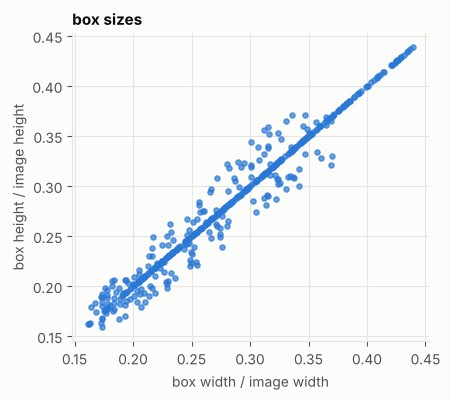

median object covers 7.5% of the image area


In [4]:
sizes = np.array([[(a["bbox"][2] - a["bbox"][0]) / im["width"], (a["bbox"][3] - a["bbox"][1]) / im["height"]]
                  for im in items for a in im["annotations"]])
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.scatter(sizes[:, 0], sizes[:, 1], s=14, color=BLUE, alpha=0.7)
ax.set_xlabel("box width / image width"); ax.set_ylabel("box height / image height"); ax.set_title("box sizes")
plt.show()
print(f"median object covers {np.median(sizes[:, 0] * sizes[:, 1]):.1%} of the image area")

## Check the boxes sit on the objects
The most valuable cell here. Wrong box format shows up instantly as boxes that are shifted, too small, or outside the image.

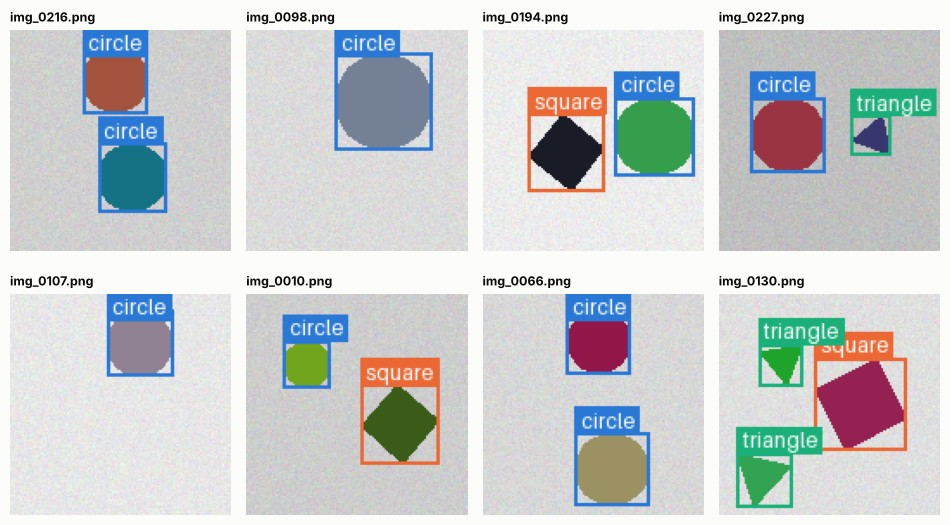

In [5]:
import random
from cvkit.viz import image_grid

rng = random.Random(0)
pick = rng.sample(items, min(8, len(items)))
_ = image_grid([draw_boxes(Image.open(im["path"]), [a["bbox"] for a in im["annotations"]], [a["label"] for a in im["annotations"]], classes=classes) for im in pick],
               [Path(im["path"]).name for im in pick], cols=4, cell=2.4)

## Augmentation
Detection augmentation has to move the **boxes together with the pixels** — a flipped image with unflipped boxes is garbage. The kit uses torchvision's v2 transforms, which do exactly that. Same image, four draws:

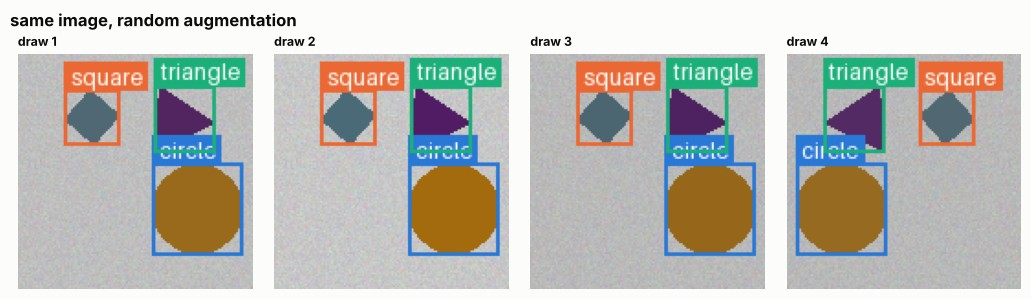

In [6]:
import torch
from torchvision.transforms.functional import to_pil_image
from cvkit.detection import build_coco_datasets
from cvkit.viz import draw_boxes, image_grid

train_ds = build_coco_datasets(cfg)["train"]
shown = []
for _ in range(4):
    img, tgt = train_ds[0]                          # a fresh random draw each time
    shown.append(draw_boxes(to_pil_image(img), tgt["boxes"].as_subclass(torch.Tensor).numpy(), tgt["labels"].numpy(), classes=train_ds.images and classes))
_ = image_grid(shown, [f"draw {i}" for i in range(1, 5)], cols=4, cell=2.6, suptitle="same image, random augmentation")

## What the model will actually receive
One batch from the training loader, exactly as `train()` gets it:

In [7]:
from cvkit.detection import build_coco_loaders

loaders = build_coco_loaders(cfg)
images, targets = next(iter(loaders["train"]))
print(f"a batch is a tuple of {len(images)} images (not one stacked tensor: sizes may differ)")
print("image:", tuple(images[0].shape), images[0].dtype, "| target keys:", list(targets[0]))
print("boxes:", tuple(targets[0]["boxes"].shape), "(N, 4) as x0, y0, x1, y1 | labels:", targets[0]["labels"].tolist(), "(0 is reserved for background)")

a batch is a tuple of 8 images (not one stacked tensor: sizes may differ)
image: (3, 128, 128) torch.float32 | target keys: ['boxes', 'labels']
boxes: (1, 4) (N, 4) as x0, y0, x1, y1 | labels: [3] (0 is reserved for background)


## Before moving on
- [ ] Boxes are drawn on the objects, not beside them
- [ ] You know the smallest object size and set `image_size` accordingly
- [ ] Every class you care about has enough boxes (dozens at least)
- [ ] Empty images are intentional

Next: **[02_train_and_evaluate](02_train_and_evaluate.ipynb)**.